In [ ]:
#@title Install requirements
!pip install -q gradio==4.27.0 diffusers==0.27.2 accelerate==0.29.3 Faker==24.11.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 35.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 69.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 297.6/297.6 kB 26.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 68.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.9/91.9 kB 8.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 313.6/313.6 kB 21.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.1/141.1 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 29.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.2/47.2 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.9/129.9 kB 9.4 MB/s eta

In [ ]:
#@title Init model

import torch
from diffusers import AnimateDiffPipeline, DDIMScheduler, MotionAdapter

adapter = MotionAdapter.from_pretrained("guoyww/animatediff-motion-adapter-v1-5-2", torch_dtype=torch.float16)
pipe2 = AnimateDiffPipeline.from_pretrained("emilianJR/epiCRealism", motion_adapter=adapter, torch_dtype=torch.float16)
scheduler = DDIMScheduler.from_pretrained(
    "emilianJR/epiCRealism",
    subfolder="scheduler",
    clip_sample=False,
    timestep_spacing="linspace",
    beta_schedule="linear",
    steps_offset=1,
)
pipe2.scheduler = scheduler
pipe2.enable_vae_slicing()
pipe2.enable_model_cpu_offload()

def disabled_safety_checker(images, clip_input):
    if len(images.shape)==4:
        num_images = images.shape[0]
        return images, [False]*num_images
    else:
        return images, False
pipe2.safety_checker = disabled_safety_checker

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:80: UserWarning: 
Access to the secret `HF_TOKEN` has not been granted on this notebook.
You will not be requested again.
Please restart the session if you want to be prompted again.
  warnings.warn(


config.json:   0%|          | 0.00/455 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.82G [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.10/dist-packages/transformers/models/clip/feature_extraction_clip.py:28: FutureWarning: The class CLIPFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use CLIPImageProcessor instead.
  warnings.warn(
The config attributes {'center_input_sample': False, 'flip_sin_to_cos': True, 'freq_shift': 0, 'mid_block_type': 'UNetMidBlock2DCrossAttn', 'only_cross_attention': False, 'attention_head_dim': 8, 'dual_cross_attention': False, 'class_embed_type': None, 'addition_embed_type': None, 'num_class_embeds': None, 'upcast_attention': False, 'resnet_time_scale_shift': 'default', 'resnet_skip_time_act': False, 'resnet_out_scale_factor': 1.0, 'time_embedding_type': 'positional', 'time_embedding_dim': None, 'time_embedding_act_fn': None, 'timestep_post_act': None, 'conv_in_kernel': 3, 'conv_out_kernel': 3, 'projection_class_embeddings_input_dim': None, 'class_embeddings_concat': False, 'mid_block_only_cross_attention': None, 'cross_attentio

In [ ]:
#@title Default Values & Main function

from diffusers.utils import load_image, export_to_video, export_to_gif
from faker import Faker
fake = Faker()

#@markdown ## Defalut Values
d_prompt="a guy trying to stop running train wearing a Spiderman suit" #@param { type: "string" }
d_pre_prompt=", high quality, 4k, hd" #@param { type: "string" }
d_negative_prompt="ugly, disfigured, low quality, blurry, weird hand, distorted, discontinuous, low resolution, motionless, static, disfigured, disconnected limbs, ugly faces, incomplete arms" #@param { type: "string" }
d_steps=30 #@param { type: "integer" }
d_seed=0 #@param { type: "integer" }
d_height=800 #@param { type: "integer" }
d_width=800 #@param { type: "integer" }

def create_image(
    prompt=d_prompt,
    pre_prompt=d_pre_prompt,
    negative_prompt=d_negative_prompt,
    steps=d_steps,
    seed=d_seed,
    height=d_height,
    width=d_width,
):
    if seed == 0:
        seed = fake.pyint()

    frames = pipe2(
        prompt=prompt + pre_prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        generator=torch.manual_seed(seed)
    ).frames[0]

    filename = fake.file_name(extension='gif')
    export_to_gif(frames, filename)
    print(filename)
    return [filename]

  0%|          | 0/30 [00:00<?, ?it/s]

lot.gif


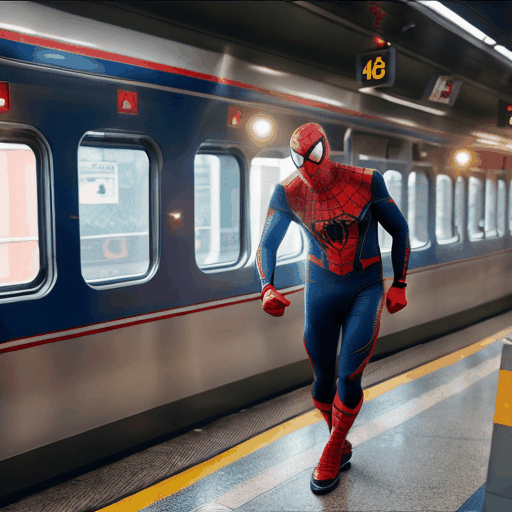

In [ ]:
#@title Cretate Image

from IPython.display import display, Image, Video

#@markdown ## Defalut Values
prompt="a guy trying to stop a running train wearing spider man suit,the man should be pushing the train" #@param { type: "string" }
negative_prompt="ugly, disfigured, low quality, blurry, weird hand, distorted, discontinuous, low resolution, motionless, static, disfigured, disconnected limbs, ugly faces, incomplete arms" #@param { type: "string" }
steps=30 #@param { type: "integer" }
seed=70 #@param { type: "integer" }
height=800 #@param { type: "integer" }
width=800 #@param { type: "integer" }

image = create_image(prompt, d_pre_prompt, negative_prompt, steps, seed, height, width)

Image(image[0])

In [ ]:
#@title Start UI

import gradio as gr

name="Text2Video"
tag_line="Transforming Text Into Digital Media"

with gr.Blocks(theme=gr.themes.Soft(), title=f"{name}: {tag_line}", css="footer {visibility: hidden}") as demo:
    gr.HTML(f"<h1><center>🖼️ {name}</center></h1>")
    gr.HTML(f"""
        <center>{tag_line}<center>
        <center>Made by <strong>Hemant Gupta, Aman Varma, Ashish Yadav & Krishna Yadav</strong></center>
    """)

    prompt=gr.TextArea(label="Prompt", value=d_prompt, lines=3, autofocus=False)

    with gr.Row():
        pre_prompt=gr.TextArea(label="Pre Prompt", value=d_pre_prompt, lines=1)
        nag_prompt=gr.TextArea(label="Nagative Prompt", value=d_negative_prompt, lines=1)

    with gr.Row():
        steps = gr.Slider(0, 200, d_steps, label="Steps", step=1)
        seed = gr.Number(label="Seed", value=d_seed)

    with gr.Row():
        height=gr.Number(label="Height", value=d_height)
        width=gr.Number(label="Width", value=d_width)

    gr.Button(value="Run").click(
        create_image,
        [ prompt, pre_prompt, nag_prompt, steps, seed, height, width ],
        gr.Gallery(label="Generated Videos")
    )

if __name__ == "__main__":
    demo.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
Running on public URL: https://be53c7d6a6affecfd6.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from Terminal to deploy to Spaces (https://huggingface.co/spaces)


  0%|          | 0/30 [00:00<?, ?it/s]

another.gif


  0%|          | 0/30 [00:00<?, ?it/s]

avoid.gif


...

whose.gif


  0%|          | 0/30 [00:00<?, ?it/s]

property.gif


  0%|          | 0/30 [00:00<?, ?it/s]

she.gif
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://be53c7d6a6affecfd6.gradio.live


In [ ]:
torch.cuda.empty_cache()